# Exercises week 44: cross-validating your Project 2 network with scikit-learn

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 26–30, 2026**

**Deadline: Friday October 30 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

You have a neural network of your own that fits the Runge function
(Project 2, parts b–d). What you do not yet have is a defensible way of
*choosing* what went into that fit — the learning rate, the regularisation
parameter and, if you wish, the number of hidden units and layers and the
number of epochs — without touching the test set. Every number you report on the test set must
come from a model whose every choice was made on training data alone, and
the way to make those choices is cross-validation (Section 2.12 of the
lecture notes; Section 3.14 did it for Ridge and Lasso in Project 1).

This week you do not write the cross-validation loop yourself. You wrap your
own network in the small interface that `scikit-learn` expects of an
estimator, and then `scikit-learn`'s machinery — `KFold`,
`cross_val_score`, `cross_validate`, `GridSearchCV`, `validation_curve` —
does the folds, the scaling inside the folds, the grid and the bookkeeping
for you, exactly as it would for one of its own models. The same wrapper
works for the MNIST classifier (exercise 3, optional). Writing the
cross-validation loop yourself is **optional** (exercise 4): the end of the
notebook shows how the loop looks when written by hand and checks that it
reproduces `scikit-learn`'s numbers to every digit — try it first, then
compare.

- **Exercise 1** (six short questions) tests whether you know what a
  cross-validation estimate is and what can go wrong with it.
- **Exercise 2** cross-validates your Project 2 regression network: the
  wrapper, the learning rate and penalty, the polynomial benchmark on the
  same folds, and the test set used once; the architecture and the number
  of epochs (parts c and d) are optional.
- **Exercise 3** (optional) does the same for the MNIST classifier with
  stratified folds and the out-of-fold confusion matrix.
- **Exercise 4** (optional) is the cross-validation loop written by hand,
  with the worked solution in the notebook.

**What is required and what is optional.** In this week's exercises and in
Project 2 you are asked to cross-validate the **learning rate $\gamma$ and
the penalty $\lambda$ in front of the $L_2$ or $L_1$ norm**. Cross-validating
the network parameters — the depth, the number of nodes, the activation
function — and the number of epochs is **optional**, both here and in
Project 2. Parts c) and d) of exercise 2 show how it is done with the same
machinery, so that you can do it if you want to; the required parts are
2a, 2b, 2e and 2f.

The network is your Project 2 code (or the week-41 code of the lecture
notebooks); seed 2026 throughout. Cross-validating a network costs $k$
folds times every point of a grid times every epoch, so plan your runs:
on the 100 Runge points everything below takes minutes, on MNIST use the
subset the exercise prescribes.

**Reading:** Sections 2.9–2.12 (generalisation, bias–variance, bootstrap,
cross-validation), 3.14 (choosing a penalty by cross-validation, the
one-standard-error rule) and 8.12 (regularisation and hyperparameters of a
network) of the lecture notes; the `scikit-learn` user guide on
[cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html),
[tuning the hyper-parameters](https://scikit-learn.org/stable/modules/grid_search.html)
and [developing estimators](https://scikit-learn.org/stable/developers/develop.html);
Hastie, Tibshirani and Friedman, Sections 7.10–7.11; Raschka et al.,
Chapter 6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp  

np.random.seed(2026)

# your network from Project 2 goes here (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed,
    ):
        self.network_input_size = network_input_size
        self.layer_output_sizes = layer_output_sizes
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders 
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.rng = np.random.default_rng(seed) # Reproducability

        # create layers = [(W , b)] with random normal weights and biases
        layers = []

        i_size = network_input_size
        for layer_output_size in layer_output_sizes:
            W = self.rng.standard_normal((i_size, layer_output_size)) / np.sqrt(i_size) # dele på sqrt(i_size)? Ja for batched
            b = np.zeros(layer_output_size) + 0.01 #np.random.randn(layer_output_size)
            layers.append((W, b))

            i_size = layer_output_size
        
        self.layers = layers

    def predict(self, inputs):
        # Simple feed forward pass
        a = jnp.asarray(inputs) 
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def cost(self, inputs, targets):
        predictions = self.predict(inputs)
        mse = self.cost_fun(predictions,targets)
        return mse

    def _feed_forward_saver(self, inputs):
        layer_inputs = []
        zs = []
        a = jnp.asarray(inputs)
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            #print("a",a.shape)
            #print("W",W.shape)
            #print("b", b.shape)
            z = a @ W + b
            zs.append(z)
            a = activation_func(z)
        return layer_inputs, zs, a 

    def compute_gradient(self, inputs, targets):
        # Backpropagation
        # dC_dW = dC_da @ da_dz @ dz_dW
        # dC_db = dC_da @ da_dz @ dz_db
        layer_inputs, sz, predict = self._feed_forward_saver(
            inputs)
        layer_grads = [() for layer in self.layers]

        for l in reversed(range(len(self.layers))):
            layer_input, z, activation_der = layer_inputs[l], sz[l], self.activation_ders[l]

            if l == (len(self.layers) - 1): # last layer
                dC_da = self.cost_der(predict, targets)
            else:
                (W, b) = self.layers[l + 1]
                #print("layer", l)
                #print("predictions:", predict.shape)
                #print("targets:", targets.shape)
                #print("dC_dz:", dC_dz.shape)
                #print("W:", W.shape)
                dC_da = dC_dz @ (W.T) 

            dC_dz = dC_da * activation_der(z) # Hadamard
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis=0) # what happened here?

            layer_grads[l] = (dC_dW, dC_db)
            #print("layer", l)
            #print("predictions:", predict.shape)
            #print("targets:", targets.shape)
            #print("dC_dz:", dC_dz.shape)
        return layer_grads
    
    def accuracy(self, predictions, targets):
        one_hot_predictions = np.zeros(predictions.shape)

        for i, prediction in enumerate(predictions):
            one_hot_predictions[i, np.argmax(prediction)] = 1
        return accuracy_score(one_hot_predictions, targets) # ski-kit function

In [2]:
class Optimizer:
    """Oppdaterer nettverkslag med plain gradient descent, Adam eller RMSprop."""

    def __init__(
        self, method, gamma,
        beta1=0.9, beta2=0.999, rho=0.99, eps=1e-8
    ):
        self.method = method.lower()
        self.gamma = gamma
        self.beta1 = beta1
        self.beta2 = beta2
        self.rho = rho
        self.eps = eps

        self.state = None
        self.t = 0

    def zero_state(self, layers):
        """Lag nullstilte momentverdier for Adam og RMSprop."""
        return [
            (
                np.zeros_like(W),  # mW
                np.zeros_like(b),  # mb
                np.zeros_like(W),  # vW
                np.zeros_like(b),  # vb
            )
            for W, b in layers
        ]

    def initialize(self, layers):
        """Start en ny treningskjøring."""
        self.t = 0

        if self.method == "plain":
            self.state = None
        else:
            self.state = self.zero_state(layers)

    def step(self, layers, layer_grads, gamma=None):
        """Utfør én minibatchoppdatering."""
        if gamma is None:
            gamma = self.gamma

        self.t += 1

        if self.method == "plain":
            return self.step_plain(layers, layer_grads, gamma)

        if self.state is None:
            raise RuntimeError("Kjør optimizer.initialize(layers) før trening.")

        if self.method == "adam":
            return self.step_adam(layers, layer_grads, gamma)

        if self.method == "rmsprop":
            return self.step_rmsprop(layers, layer_grads, gamma)

        raise ValueError("method må være 'plain', 'adam' eller 'rmsprop'")

    def step_plain(self, layers, layer_grads, gamma):
        return [
            (W - gamma * dW, b - gamma * db)
            for (W, b), (dW, db) in zip(layers, layer_grads)
        ]

    def step_rmsprop(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            vW = self.rho * vW + (1 - self.rho) * dW**2
            vb = self.rho * vb + (1 - self.rho) * db**2

            W = W - gamma * dW / (np.sqrt(vW) + self.eps)
            b = b - gamma * db / (np.sqrt(vb) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

    def step_adam(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            mW = self.beta1 * mW + (1 - self.beta1) * dW
            mb = self.beta1 * mb + (1 - self.beta1) * db
            vW = self.beta2 * vW + (1 - self.beta2) * dW**2
            vb = self.beta2 * vb + (1 - self.beta2) * db**2

            mW_hat = mW / (1 - self.beta1**self.t)
            mb_hat = mb / (1 - self.beta1**self.t)
            vW_hat = vW / (1 - self.beta2**self.t)
            vb_hat = vb / (1 - self.beta2**self.t)

            W = W - gamma * mW_hat / (np.sqrt(vW_hat) + self.eps)
            b = b - gamma * mb_hat / (np.sqrt(vb_hat) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

In [3]:
def step_length(t, t0, t1):
    """A decaying learning-rate schedule."""
    return t0 / (t + t1)

def train_sgd(
    network, X, y, method="adam",
    epochs=100, batch_size=5, gamma=0.001, lmb = 0.0, penalty ="l2", schedule=None, seed=2026
):
    "LLM Assisted: Using the class netowrk"
    rng = np.random.default_rng(seed)

    X = np.asarray(X)
    y = np.asarray(y).reshape(-1, 1)

    # Bruk av klasse
    optimizer = Optimizer(method=method, gamma=gamma)
    optimizer.initialize(network.layers)

    # Tilstanden er en liste med tupler, ett for hvert lag.
    state = None if method == "plain" else optimizer.zero_state(network.layers)
    t = 0
    history = []
    history_test = []
    
    for epoch in range(epochs):
        # Bland rekkefølgen på datapunktene for hver epoke.
        indices = rng.permutation(len(X))
        # Minibatch
        for start in range(0, len(X), batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X[batch]
            y_batch = y[batch]

            # Hent gradientene fra nettverksobjektet.
            layer_grads = network.compute_gradient(X_batch, y_batch)

            #L2 norm - Ridge
            "AI Declaration: Help from codex GPT-LUNA6.1 for task 2b) L1 and L2 placement"
            if penalty == "l2":
                layer_grads = [
                (dW + 2 * lmb * W, db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)]
            #L1 norm - Lasso
            #"AI Declaration: Help from codex GPT-Luna6.1"
            elif penalty == "l1":
                layer_grads = [
                (dW + lmb * np.sign(W), db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)
                ]
            elif penalty is not None:
                raise ValueError("penalty må være 'l1', 'l2' eller None")

            # Tell minibatchoppdateringer. Adam bruker t til korreksjon
            # for oppstartsfasen.
            t += 1
            gamma = gamma if schedule is None else step_length(t - 1, *schedule)
            network.layers = optimizer.step(network.layers, layer_grads)

        # Kostnaden etter at hele treningssettet har vært gjennom én gang.
        epoch_cost = float(network.cost(X, y))
        history.append(epoch_cost)
    

    return history, network.layers

In [4]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def mse(predict, target):
    return jnp.mean((predict - target) ** 2)
def mse_der(predict, target): # Derivative of cost function
    return 2*(predict - target)/predict.size # Mean brings a factor of 1/N, derivative brings factor 2


ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

print(ACTIVATIONS["sigmoid"][1])
"""OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax} # Denne er unødvendig enn så lenge
da Neuralnetwork bruker mse"""

<function sigmoid_prime at 0x126815620>


'OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax} # Denne er unødvendig enn så lenge\nda Neuralnetwork bruker mse'

In [5]:
from sklearn.model_selection import train_test_split

def Data_process(x, y, degree, 
    test_size = 0.3, Process="Split and scale"):
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1,1)
    X = np.column_stack([x**power for power in range(degree + 1)])

    if Process == "Split and scale":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=2026
        )

        # Scale polynomial features, leaving the intercept column unchanged.
        mean = X_train[:, 1:].mean(axis=0)
        std = X_train[:, 1:].std(axis=0)
        mean[0] = 0
        std[std == 0] = 1

        X_train[:, 1:] = (X_train[:, 1:] - mean) / std
        X_test[:, 1:] = (X_test[:, 1:] - mean) / std

        y_mean = y_train.mean(axis=0)
        y_train_c = y_train - y_mean

        return X_train, X_test, y_train_c, y_test, y_mean
    
    if Process == "Scale":
        mean = X[:, 1:].mean(axis=0)
        std = X[:, 1:].std(axis=0)
        mean[0]=0
        std[std == 0] = 1
        
        X[:, 1:] = (X[:, 1:] - mean) / std

        y_mean = y.mean(axis=0)
        y_c = y - y_mean
        
        return X, y, y_mean

## Exercise 1: pencil and paper — what cross-validation estimates, and what can go wrong

**a)** State in one sentence what the $k$-fold cross-validation error
estimates (Section 2.12): the error of *which* model, trained on how much
data, evaluated on what? Why is it an estimate of the generalisation error
of the training *procedure* rather than of the one network you finally
train on all the data?

**b)** With $k$ folds you obtain $k$ numbers $e_1,\dots,e_k$. Give the mean
and its standard error, $\bar e\pm s/\sqrt{k}$, and explain why the $k$
numbers are not independent (two training sets share $(k-2)/(k-1)$ of their
samples), so that this standard error is optimistic. What happens to the
bias and the variance of the estimate as $k$ goes from $2$ to $n$
(leave-one-out)?

**c)** Scaling. You standardise the inputs before training. Explain why the
scaler must be *fitted inside each fold* on the training part only, and name
one concrete number that leaks if it is fitted on all the data first. This
is what a `scikit-learn` `Pipeline` guarantees — say in one sentence how.

**d)** A colleague trains ten networks with ten learning rates, reports the
test MSE of each, and writes "the best learning rate is $0.01$, with a test
MSE of $0.0094$". Name the two things that are wrong with that sentence and
write the honest version of it.

**e)** Early stopping. Explain why the number of epochs is a hyperparameter
like any other, how a validation fold is used to choose it (the epoch at
which the validation error is smallest), and why the training error is
useless for that purpose.

**f)** The one-standard-error rule (Section 3.14). You have the
cross-validated MSE and its standard error for
$\lambda\in\{0,10^{-5},\dots,10^{-2}\}$. State the rule and explain why it
prefers the *more* regularised model among those within one standard error
of the best — and what "more regularised" means for a network when the grid
is over hidden units rather than over $\lambda$.

a) The k-fold cv error estimates the error of the model used, the data is shuffled at random and divided into k fold, the model is trained on k-1 folds and tested on the k´th fold, this is done so that all k folds are held out once. It is an estimate of the generalisation error of the training procedure since the data is trained on parts of the data, which is the same size for each cross validation, this will give different scores for each validation, since the training is given different data for each cross validation, the mean of all k-folds will give an estimate of the generalisation error of the training procedure. When the final model is tested on all the data, the traind model will have different parameters than that from the k-fold cv. 

b)
1. Mean, $\bar{e} = \sum_{i=[1,k]}\frac{e_i}{k}$.  
   Standard deviation: $s = \sigma=\sqrt{\sum_{i=[1-k]}\frac{(\bar{y} - \tilde{y})^2}{k-1}}$
   Standard error: $SE = s/\sqrt{k}$
2. Any two fold models training sets share (k-2)/(k-1) of their training observations, so their error tends to be correlated. --> This makes $s/sqrt{k}$ an optimistic uncertainty estimate. 
3. At k = 2, each model trains on only half of the data, so the estimate tends to be more biased upward. The two training sets overlaps less, so the variance is lower.
   As k increases, each model trains on more data, reducing the bias. But the training overlap more, so the fold error become more correlated and the estimate variance tends to increase.  
   At k = n, this is leave-one-out, the maximum variance and lowest bias possible. We see also from the standard error formula that it decreases as k-increases.  
   I do not really know what the variance here is pointing two..

c) The mean of the data set will leak if it is fitted on all the data, this will affect the training data, giving information about the test data. 
The pipeline makes sure the scaler is fitted only on each folds training data, and then using the same scaler on the held out validation data after fitting.

d) The first fault is that the test MSE is the qualification for choosing the best learning rate, the second is that  and there is no uncertainty reported for the traning (K-fold) mse, which is important for comparison.  
"Kfold cross validation selected $\gamma = 0.001$ as the best learning rate, with CV MSE 0.002 +- SE. After refitting on all training data, the test MSE was 0.004, evaluated once. 

e)  The number of epochs is a variable which we set, and it affects how the model fits and generalises. The validation fold is when the model is tested on the left out fold, increasing the number of epochs will make the model better fit the training data, but can lead to overfitting, and thus the validation error can begin increasing, the bias variance tradeoff: increasing the number of epochs will decrease the bias, but the variance will increase, an increase of variance, from the validation error, will indicate that a threshold is reached, even though the training error will keep on decreasing. 

f) If there exists a more regularized model within one standard error of the best, there is no reliable way to choose between the models, and the most simple model should be chosen for efficiency; of all the models within/ below the lowest CV MSE + standard error threshold. For a network a more regularized network when the grid is over hidden units means a network with less hidden units, a simpler network.

## Exercise 2: your network inside scikit-learn's cross-validation — the Runge regression of Project 2

### a) The wrapper: your network as a scikit-learn estimator

`scikit-learn`'s cross-validation functions do not care how a model is
built; they only call a handful of methods. A class that provides them is an
*estimator*, and `KFold`, `cross_val_score`, `GridSearchCV` and `Pipeline`
accept it like any built-in model. The rules are few:

1. **`__init__` stores its arguments and does nothing else.** Every
   hyperparameter is a keyword argument with a default, stored under *the
   same name* (`self.gamma = gamma`). `BaseEstimator` then provides
   `get_params()` and `set_params()` automatically — this is how
   `GridSearchCV` sets `gamma` and `lmbd` for every point of the grid — and
   `clone()` makes the fresh, untrained copy that every fold starts from.
2. **`fit(X, y)` does all the work** — creates the layers from the seed,
   trains, stores the result in attributes ending in an underscore
   (`self.layers_`) — **and returns `self`.**
3. **`predict(X)` returns a 1D array** for regression; `RegressorMixin`
   then supplies `score()` (the $R^2$), and we will ask for the MSE
   explicitly.

Fill in `fit` and `predict` around your own network (the `...` lines).
Nothing else in this notebook depends on how your network is written.

In [6]:
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Your Project 2 network with the scikit-learn estimator interface."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.01, lmbd=0.0, epochs=100, batch_size=10, seed=2026):
        # store the hyperparameters under the same names; no computation here
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        # X has shape (n, 1), y shape (n,): build the layers from self.seed,
        # train with your SGD for self.epochs epochs, store the layers in self.layers_

        """LLM Assistance: Creating the activation funcs in correct format"""
        hidden_func, hidden_der = ACTIVATIONS[self.activation]
        activation_funcs = [hidden_func] * len(self.hidden) + [identity]
        activation_ders = [hidden_der] * len(self.hidden) + [identity_prime]

        self.network_ = NeuralNetwork(
            network_input_size=X.shape[1],
            layer_output_sizes=(*self.hidden,1), # LLM Assisted - Shape error
            activation_funcs= activation_funcs,
            activation_ders = activation_ders,
            cost_fun=mse,
            cost_der=mse_der,
            seed=self.seed
        )

        self.history, self.layer = train_sgd(
        self.network_, X, y, method ="plain",
        epochs = self.epochs, batch_size = self.batch_size, 
        gamma = self.gamma, lmb = self.lmbd, penalty="l2", seed = self.seed)
        return self

    def predict(self, X):
        """LM Assisted: Use of class functionality
           LM Assisted: Reshaping of output array to 1D for Scikit""" 
        # the network output as a 1D array of length len(X)
        predictions = self.network_.predict(X)
        predictions_1D = np.asarray(predictions).reshape(-1)
        return predictions_1D


# the data of Project 2, part b)
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)

In [7]:
hidden_func, hidden_der = ACTIVATIONS["sigmoid"]
activation_funcs = [hidden_func] * len((50,)) + [identity]
activation_ders = [hidden_der] * len((50,)) + [identity_prime]
print(len((50,)))
print(*(50,),1)

1
50 1


**Check the wrapper** before cross-validating anything: `fit` on all
100 points, `predict` on them, and compare the training MSE with the number
your own training loop prints for the same settings — they must agree to
every digit. 

In [8]:
# NeuralNetRegressor
NN = NeuralNetRegressor()
NN.fit(X, y)
prediction = NN.predict(X)

In [9]:
#y_reshape = y.reshape(-1) # må endre tilbake da y er tilpasset scikit
MSE = mse(prediction, y)
print("MSE:", MSE)

MSE: 0.10305659664454758


In [10]:
# Regular solution
network_input_size = X.shape[-1] # 9
layer_output_sizes1 = [50, 1]
activation_funcs1 =[sigmoid, identity]
activation_ders1 =[sigmoid_prime, identity_prime]
gamma = 0.01
epochs=100
batch_size=10

NN_plain = NeuralNetwork(network_input_size, layer_output_sizes1, 
activation_funcs1, activation_ders1, mse, mse_der, seed=2026)
plain_history, last_layer = train_sgd(NN_plain, X, y, method="plain",
epochs=100, batch_size=10, gamma=0.01, lmb=0.0)

In [11]:
print("Regular plain MSE:", plain_history[-1])

Regular plain MSE: 0.10305659664454758


In [12]:
# Final agreement
print("The methods agree to numerical precision:",np.allclose(MSE, plain_history[-1]))

The methods agree to numerical precision: True


Then run the three lines below. `KFold(5, shuffle=True,
random_state=2026)` fixes the folds for the whole exercise; the `Pipeline`
puts the scaler *inside* each fold; `cross_val_score` returns one score per
fold, as a negative MSE (`scikit-learn` maximises scores).  
* Report the mean and the standard error $s/\sqrt{k}$ of the five validation MSEs.
* Report the training MSEs from `cross_validate(..., return_train_score=True)` next to them

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
net = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=0.03, epochs=100))
scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)

In [14]:
print("-cross_val_score:")
print(f"5-fold CV MSE {scores.mean():.4f} +/- {scores.std(ddof=1) / np.sqrt(len(scores)):.4f}")
print(f"folds: {scores}")
print("cross_validate:")
#print(res)
validation_mse = -res["test_score"]
training_mse = -res["train_score"]
print("5 Fold Test score:", validation_mse)
print("5 Fold train score:", training_mse)

mean_mse = validation_mse.mean()
std_error = validation_mse.std(ddof=1) / np.sqrt(len(validation_mse))

print(f"CV MSE: {mean_mse:.4f} +/- {std_error:.4f}")

print("The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent")

-cross_val_score:
5-fold CV MSE 0.0985 +/- 0.0092
folds: [0.11818073 0.11803193 0.07845016 0.10208871 0.07572281]
cross_validate:
5 Fold Test score: [0.11818073 0.11803193 0.07845016 0.10208871 0.07572281]
5 Fold train score: [0.09200558 0.09206376 0.09726874 0.0948162  0.09112715]
CV MSE: 0.0985 +/- 0.0092
The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent


### b) Learning rate and penalty with `GridSearchCV`

`GridSearchCV` takes the pipeline, a grid of parameter values addressed as
`<step name>__<parameter>`, the `cv` object and a scoring rule, fits every
combination on every fold, and stores everything in `cv_results_`
(`mean_test_score`, `std_test_score`, `mean_train_score`, `params`, …).
With `refit=True` (the default) it finally retrains the best combination on
*all* the data and exposes it as `best_estimator_`.

Cross-validate your one-hidden-layer network over
$\gamma\in\{0.001, 0.003, 0.01, 0.03, 0.1\}$ and
$\lambda\in\{0, 10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}\}$ at a fixed
architecture and number of epochs. 

In [15]:
param_grid = {"neuralnetregressor__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
              "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-4, 1e-3, 1e-2]}
search = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
search.fit(X, y)
# 9m 9.8s

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...gamma=0.03))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'neuralnetregressor__gamma': [0.001, 0.003, ...], 'neuralnetregressor__lmbd': [0.0, 1e-05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be ava

In [33]:
results = search.cv_results_          # a dict of arrays, one entry per grid point
cv_mse_grid = -results["mean_test_score"]
cv_se_grid = results["std_test_score"] / np.sqrt(cv.get_n_splits() - 1)
print("mse grid")
print(cv_mse_grid)
print("se grid")
print(cv_se_grid)
print("-----")
best_estimator = search.best_estimator_
best_params = search.best_params_
print(best_estimator)
print(best_params)
print("-----")
print("Final Result:\n")
best_mse = -search.best_score_  # Ved scoring="neg_mean_squared_error"
best_index = search.best_index_
k = search.n_splits_
best_se = search.cv_results_["std_test_score"][best_index] / np.sqrt(k - 1)
print(f"best_mse = {best_mse:.4f} +/- best_se = {best_se:.4f}")
print(f"gamma = {best_params["neuralnetregressor__gamma"]}, lambda = {best_params["neuralnetregressor__lmbd"]}")
print("OLS with learning rate 0.1")

print("-------")
"AI Declaration: GPT-Luna6 help with indexing and for loop"
threshold = cv_mse_grid[best_index] + cv_se_grid[best_index]
print(f"One-SE limit:  {threshold:.5f}\n")
found = False
for i, params in enumerate(results["params"]):
    gamma = params["neuralnetregressor__gamma"]
    lmbd = params["neuralnetregressor__lmbd"]

    if lmbd > 0 and cv_mse[i] <= threshold:
        found = True
        print(
            f"gamma={gamma:g}, lambda={lmbd:g}: "
            f"CV-MSE={cv_mse[i]:.5f} +/- {cv_se[i]:.5f}"
        )

if not found:
    print("No positive Ridge penalties gave a CV-MSE within one SE of the lowest.")


mse grid
[0.1063432  0.1063432  0.10634324 0.10634358 0.10634678 0.10586085
 0.10586097 0.10586198 0.10587208 0.10596685 0.10420513 0.10420637
 0.10421749 0.10432649 0.10521953 0.09849486 0.09850801 0.0986256
 0.09974119 0.10633958 0.03145823 0.03149922 0.03186689 0.03542819
 0.08558055]
se grid
[0.01121886 0.01121883 0.01121857 0.011216   0.01119048 0.01114094
 0.01114089 0.01114044 0.01113591 0.01109174 0.0103555  0.01035548
 0.01035526 0.01035295 0.01031636 0.00922633 0.00922695 0.00923249
 0.00928142 0.0093125  0.00321659 0.00322039 0.00325457 0.00361638
 0.0091364 ]
-----
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor', NeuralNetRegressor(gamma=0.1))])
{'neuralnetregressor__gamma': 0.1, 'neuralnetregressor__lmbd': 0.0}
-----
Final Result:

best_mse = 0.0315 +/- best_se = 0.0032
gamma = 0.1, lambda = 0.0
OLS with learning rate 0.1
-------
One-SE limit:  0.03467

gamma=0.1, lambda=1e-05: CV-MSE=0.03150 +/- 0.00322
gamma=0.1, lambda=0.0001:

From `cv_results_` draw the CV MSE as a
heat map (the figure part c) of Project 2 asks for) with the training MSE
next to it; mark the minimum and every cell within one standard error of it
(`std_test_score` is the standard deviation over the folds with `ddof=0`;
the standard error $s/\sqrt{k}$ is `std_test_score / np.sqrt(k - 1)`); apply the one-standard-error rule and state your choice. Note
that `scikit-learn` reports negative MSEs; flip the sign.

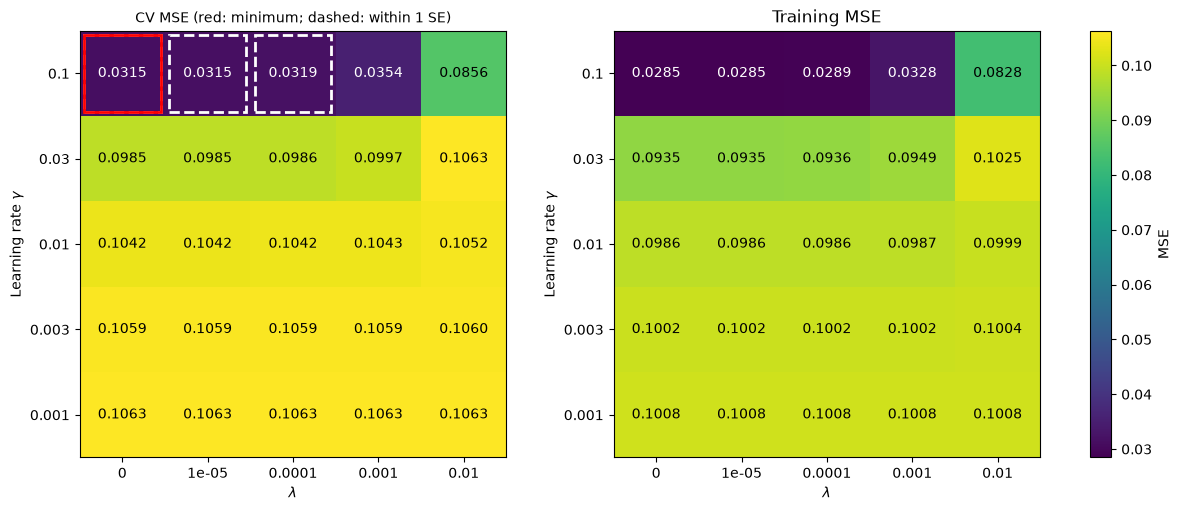

Minimum CV MSE: 0.03146; one-SE threshold: 0.03467
One-SE choice: gamma=0.1, lambda=0.0001, CV MSE=0.03187


In [17]:
# LLM Assisted(Substantial): Heat maps from the existing GridSearchCV results.
results = search.cv_results_
gammas = search.param_grid["neuralnetregressor__gamma"]
lambdas = search.param_grid["neuralnetregressor__lmbd"]
shape = (len(gammas), len(lambdas))

cv_mse_grid = -results["mean_test_score"].reshape(shape)
train_mse_grid = -results["mean_train_score"].reshape(shape)
cv_se_grid = results["std_test_score"].reshape(shape) / np.sqrt(search.n_splits_ - 1)

best_cell = np.unravel_index(np.argmin(cv_mse_grid), shape)
threshold = cv_mse_grid[best_cell] + cv_se_grid[best_cell]
within_one_se = cv_mse_grid <= threshold

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
vmin = min(cv_mse_grid.min(), train_mse_grid.min())
vmax = max(cv_mse_grid.max(), train_mse_grid.max())

for ax, values, title in zip(axes, [cv_mse_grid, train_mse_grid],
                             ["CV MSE", "Training MSE"]):
    im = ax.imshow(values, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(lambdas)), [f"{value:g}" for value in lambdas])
    ax.set_yticks(range(len(gammas)), [f"{value:g}" for value in gammas])
    ax.set_xlabel(r"$\lambda$")
    ax.set_ylabel(r"Learning rate $\gamma$")
    ax.set_title(title)
    for (row, col), value in np.ndenumerate(values):
        color = "white" if value < (vmin + vmax) / 2 else "black"
        ax.text(col, row, f"{value:.4f}", ha="center", va="center", color=color)

# Dashed white boxes: within one SE of the minimum. Red box: the minimum.
for row, col in np.argwhere(within_one_se):
    axes[0].add_patch(plt.Rectangle((col - 0.45, row - 0.45), 0.9, 0.9,
                                   fill=False, edgecolor="white", linestyle="--", linewidth=2))
row, col = best_cell
axes[0].add_patch(plt.Rectangle((col - 0.45, row - 0.45), 0.9, 0.9,
                               fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("CV MSE (red: minimum; dashed: within 1 SE)", fontsize=10)
fig.colorbar(im, ax=axes, label="MSE")
plt.show()

# One-SE rule: strongest regularization; break ties using the lowest CV MSE.
chosen_row, chosen_col = min(
    map(tuple, np.argwhere(within_one_se)),
    key=lambda cell: (-lambdas[cell[1]], cv_mse_grid[cell]),
)
print(f"Minimum CV MSE: {cv_mse_grid[best_cell]:.5f}; one-SE threshold: {threshold:.5f}")
print(f"One-SE choice: gamma={gammas[chosen_row]:g}, lambda={lambdas[chosen_col]:g}, "
      f"CV MSE={cv_mse_grid[chosen_row, chosen_col]:.5f}")


Minimum med rød ramme
Celler innen en standardfeil med striplet ramme
Parametervalget etter en standarfeil-regelen i utstriken.

«One-SE choice» er modellvalget etter én-standardfeil-regelen. SE står for standard error, altså standardfeil.

Regelen er:
1. Finn den laveste gjennomsnittlige CV-MSE-en.
2. Sett grensen til laveste CV-MSE + standardfeilen til denne.
3. Velg den enkleste modellen med CV-MSE under denne grensen.

### e) The benchmark: OLS and Ridge on the same folds

Cross-validate `make_pipeline(StandardScaler(), PolynomialFeatures(degree),
LinearRegression())` over degrees $1,\dots,15$ and the Ridge version over
degree and $\lambda$ with `GridSearchCV` on the *same* `cv` object. 

AI Declaration: Week44tuesday code + AI assistance for printing the results

In [ ]:
# Use raw x: X was already expanded into polynomial features above.
X_poly = x.reshape(-1, 1) # AI assisted
poly_OLS = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
ols = GridSearchCV(poly_OLS, {"polynomialfeatures__degree": range(1, 16)}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
ols.fit(X_poly, y) # Drives the fitting: 15 degree x 5 folds = 75 models

poly_Ridge = make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge(solver="svd"))
ridge_lambdas = (0.0, 1e-5, 1e-4, 1e-3, 1e-2)
degrees = range(1, 16)
alpha = [len(y) * l for l in ridge_lambdas] # schikit uses the alpha values for the cost
# Alpha uses the whole data set of y, instead of the fold sizes
ridge = GridSearchCV(poly_Ridge, {"polynomialfeatures__degree": list(degrees), "ridge__alpha": alpha},
                         cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
ridge.fit(X_poly, y) # Drives the fitting: 15 degrees x 5 folds x 5 penalties = 375 models 

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lver='svd'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'polynomialfeatures__degree': [1, 2, ...], 'ridge__alpha': [0.0, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`

Put the
best polynomial model and the best network (the one chosen in b) in one table:  
CV MSE $\pm$ standard error, number of parameters, fitting time (`cv_results_` has `mean_fit_time`).  
Does the network beat the polynomial, and is the difference larger than the error bars? 
 (Section 8.14 of the notes and the "What you should take away" list of Project 2 say what to expect.)

r = ols.cv_results_. 

r["params"]            # Polynomgrad for hver kandidat. 

r["mean_test_score"]   # Gjennomsnittlig negativ validerings-MSE. 

r["std_test_score"]    # Standardavvik mellom foldenes valideringsscore. 

r["mean_train_score"]  # Gjennomsnittlig negativ trenings-MSE. 

r["mean_fit_time"]     # Gjennomsnittlig tilpasningstid per fold, i sekunder. 

In [ ]:
k = cv.get_n_splits()
r = ols.cv_results_
R = ridge.cv_results_
poly = ({"ols": ols, 
        "ridge": ridge, 
        "degrees": list(degrees), 
        "ols_mse": -r["mean_test_score"],
        "ols_se": r["std_test_score"] / np.sqrt(k - 1), 
        "ols_train": -r["mean_train_score"],
        "ridge_se": R["std_test_score"] / np.sqrt(k - 1)})

d_O = poly["ols"].best_params_["polynomialfeatures__degree"] # OLS best degree

#print("OLS, CV MSE by degree:   ", np.round(poly["ols_mse"], 4))
#print("OLS, standard error:     ", np.round(poly["ols_se"], 4))
#print("OLS, training MSE:       ", np.round(poly["ols_train"], 4))
d_R = poly['ridge'].best_params_["polynomialfeatures__degree"]  # Ridge best degree
a_R = poly['ridge'].best_params_["ridge__alpha"]                # Ridge alpha
print(f"OLS: best degree {d_O}, CV MSE {-poly['ols'].best_score_:.4f} +/- {poly['ols_se'][d_O - 1]:.4f}, {d_O + 1} parameters")
print(f"Ridge: degree: {d_R} alpha = {a_R} (alpha = n*lambda)")
print(f"CV MSE = {-poly['ridge'].best_score_:.4f} +/- {poly["ridge_se"][d_R - 1]:.4f}")
print("-----")

OLS: best degree 11, CV MSE 0.0211 +/- 0.0032, 12 parameters
Ridge: {'polynomialfeatures__degree': 11, 'ridge__alpha': 0.001} (alpha = n lambda), CV MSE = 0.0208
-----


## One SE rule
Now does there exist a higher ridge penalty within one SE of the best MSE
-->  DETTE MÅ NØSTES OPP

In [34]:
# Find the lowest-MSE polynomial model across OLS and Ridge.
reference = min((ols, ridge), key=lambda model: -model.best_score_)

best_mse = -reference.best_score_
best_se = (
    reference.cv_results_["std_test_score"][reference.best_index_]
    / np.sqrt(reference.n_splits_ - 1)
)
threshold = best_mse + best_se

print(f"Lowest polynomial CV-MSE: {best_mse:.5f}")
print(f"One-SE limit: {threshold:.5f}\n")

ridge_results = ridge.cv_results_
ridge_mse = -ridge_results["mean_test_score"]
ridge_se = (
    ridge_results["std_test_score"]
    / np.sqrt(ridge.n_splits_ - 1)
)

for i, params in enumerate(ridge_results["params"]):
    degree = params["polynomialfeatures__degree"]
    alpha = params["ridge__alpha"]
    lmbd = alpha / len(y)  # Your grid uses alpha = len(y) * lambda.

    if alpha > 0 and ridge_mse[i] <= threshold:
        print(
            f"degree={degree}, lambda={lmbd:g}: "
            f"CV-MSE={ridge_mse[i]:.5f} +/- {ridge_se[i]:.5f}"
        )

Lowest polynomial CV-MSE: 0.02083
One-SE limit: 0.02388

degree=8, lambda=1e-05: CV-MSE=0.02251 +/- 0.00172
degree=8, lambda=0.0001: CV-MSE=0.02241 +/- 0.00172
degree=9, lambda=1e-05: CV-MSE=0.02373 +/- 0.00121
degree=9, lambda=0.0001: CV-MSE=0.02363 +/- 0.00127
degree=10, lambda=1e-05: CV-MSE=0.02346 +/- 0.00247
degree=10, lambda=0.0001: CV-MSE=0.02242 +/- 0.00145
degree=11, lambda=1e-05: CV-MSE=0.02083 +/- 0.00305
degree=11, lambda=0.0001: CV-MSE=0.02103 +/- 0.00207
degree=12, lambda=0.0001: CV-MSE=0.02168 +/- 0.00247
degree=13, lambda=0.0001: CV-MSE=0.02361 +/- 0.00243


Now the network

In [ ]:
"AI assisted use of search and plotting, with week44tuesday"
network_results = search.cv_results_
network_best_ind = search.best_index_
k_s = search.n_splits_
network_se = network_results['std_test_score'][network_best_ind] / np.sqrt(k_s - 1)

layer_sizes = (search.best_estimator_[0].n_features_in_, *search.best_estimator_[-1].hidden, 1)
network_params = sum((n_in + 1) * n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))

print(f"Best network: learning rate gamma={search.best_params_['neuralnetregressor__gamma']:g}, "
      f"penalty lambda={search.best_params_['neuralnetregressor__lmbd']:g}")
print(f"best grid point {-search.best_score_:.4f} +/- {network_se:.4f}, "
      f"{network_params} parameters, {network_results['mean_fit_time'][network_best_ind]:.2f} s per fit against "
      f"{poly['ols'].cv_results_['mean_fit_time'][poly['ols'].best_index_] * 1e3:.1f} ms")

the network: untuned CV MSE 0.1042 +/- 0.0104
Best network: learning rate gamma=0.1, penalty lambda=0
best grid point 0.0315 +/- 0.0032, 151 parameters, 5.19 s per fit against 3.6 ms


In [38]:
"AI assisted table"
import pandas as pd

def result_row(name, model, n_params, index=None):
    # Default to the minimum-MSE candidate.
    if index is None:
        index = model.best_index_

    results = model.cv_results_
    mse = -results["mean_test_score"][index]
    se = results["std_test_score"][index] / np.sqrt(model.n_splits_ - 1)

    settings = {
        key.split("__")[-1]: value
        for key, value in results["params"][index].items()
    }

    return {
        "Model": name,
        "Settings": settings,
        "CV MSE ± SE": f"{mse:.5f} ± {se:.5f}",
        "Parameters": n_params,
        "Fit time (ms)": round(results["mean_fit_time"][index] * 1000, 1),
    }

comparison = pd.DataFrame([
    result_row("Network", search, network_params),
    result_row(
        "OLS", ols,
        ols.best_params_["polynomialfeatures__degree"] + 1,
    ),
    result_row(
        "Ridge", ridge,
        ridge.best_params_["polynomialfeatures__degree"] + 1,
    ),
]).set_index("Model")

display(comparison)

,Settings,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Network,"{'gamma': 0.1, 'lmbd': 0.0}",0.03146 ± 0.00322,151,5192.1
OLS,{'degree': 11},0.02111 ± 0.00324,12,3.6
Ridge,"{'degree': 11, 'alpha': 0.001}",0.02083 ± 0.00305,12,3.3


In [39]:
results = search.cv_results_
mse = -results["mean_test_score"]
se = results["std_test_score"] / np.sqrt(search.n_splits_ - 1)

threshold = mse[search.best_index_] + se[search.best_index_]

eligible = np.flatnonzero(mse <= threshold)

network_one_se_index = min(
    eligible,
    key=lambda i: (
        -results["params"][i]["neuralnetregressor__lmbd"],
        mse[i],
    ),
)

params = results["params"][network_one_se_index]

print(f"One-SE limit: {threshold:.5f}")
print(f"Selected gamma:  {params['neuralnetregressor__gamma']:g}")
print(f"Selected lambda: {params['neuralnetregressor__lmbd']:g}")
print(
    f"CV MSE: {mse[network_one_se_index]:.5f} "
    f"+/- {se[network_one_se_index]:.5f}"
)

One-SE limit: 0.03467
Selected gamma:  0.1
Selected lambda: 0.0001
CV MSE: 0.03187 +/- 0.00325


In [40]:
import pandas as pd

rows = []

for name, model in [("Ridge", ridge), ("Network", search)]:
    results = model.cv_results_
    mse = -results["mean_test_score"]
    se = results["std_test_score"] / np.sqrt(model.n_splits_ - 1)

    threshold = mse[model.best_index_] + se[model.best_index_]
    eligible = np.flatnonzero(mse <= threshold)

    if name == "Ridge":
        selected = min(
            eligible,
            key=lambda i: (
                results["params"][i]["polynomialfeatures__degree"],
                -results["params"][i]["ridge__alpha"],
                mse[i],
            ),
        )
        params = results["params"][selected]
        degree = params["polynomialfeatures__degree"]
        lmbd = params["ridge__alpha"] / len(y)

        settings = f"degree={degree}, lambda={lmbd:g}"
        n_params = degree + 1

    else:
        selected = min(
            eligible,
            key=lambda i: (
                -results["params"][i]["neuralnetregressor__lmbd"],
                mse[i],
            ),
        )
        params = results["params"][selected]
        gamma = params["neuralnetregressor__gamma"]
        lmbd = params["neuralnetregressor__lmbd"]

        settings = f"gamma={gamma:g}, lambda={lmbd:g}"
        n_params = network_params

    rows.append({
        "Model": name,
        "One-SE selection": settings,
        "CV MSE ± SE": f"{mse[selected]:.5f} ± {se[selected]:.5f}",
        "Parameters": n_params,
        "Fit time (ms)": round(
            results["mean_fit_time"][selected] * 1000, 1
        ),
    })

comparison_one_se = pd.DataFrame(rows).set_index("Model")
display(comparison_one_se)

,One-SE selection,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Ridge,"degree=8, lambda=0.0001",0.02241 ± 0.00172,9,3.1
Network,"gamma=0.1, lambda=0.0001",0.03187 ± 0.00325,151,2237.8


The neural network predicts the function reasonably well, but is complex (151 parameters) and the cost shows in the fitting time (2238 ms). Ridge achieves lower validation error with fewer parameters and shorter fitting time, 9 and 3.1ms respectively, making it the preferred model for this particular experiment.

### f) The test set, once

Generate a fresh test set of 100 points with a different seed and the same
noise. `search.best_estimator_` is the chosen network retrained on all 100
training points (that is what `refit=True` did); report its test MSE
*once*, next to the cross-validated estimate and its standard error, and do
the same for the polynomial model. Are the test MSEs inside the CV error
bars? Should they be — what does the CV estimate describe, and what does
the test MSE describe (exercise 1a)?

In [41]:
rng_test = np.random.default_rng(1)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)
# Match the network's training features from Data_process(..., Process="Scale").
X_test_network = X_test
if search.best_estimator_.n_features_in_ > 1:
    network_degree = search.best_estimator_.n_features_in_ - 1
    train_powers = np.column_stack([x**power for power in range(network_degree + 1)])
    X_test_network = np.column_stack([x_test**power for power in range(network_degree + 1)])
    feature_mean = train_powers[:, 1:].mean(axis=0)
    feature_std = train_powers[:, 1:].std(axis=0)
    feature_mean[0] = 0  # Match the existing Data_process implementation.
    feature_std[feature_std == 0] = 1
    X_test_network[:, 1:] = (X_test_network[:, 1:] - feature_mean) / feature_std
# mse_test = np.mean((search.best_estimator_.predict(X_test) - y_test) ** 2)

"Week44tuesday"
def cv_test_once(search, X_test, y_test):
    """Step 6: best_estimator_ (the winner refit on all training points) on a test set it has never seen, once."""
    predictions = np.asarray(search.best_estimator_.predict(X_test)).reshape(-1)
    targets = np.asarray(y_test).reshape(-1)
    return float(np.mean((predictions - targets) ** 2))
print(f"test MSE, once: network best_estimator_ {cv_test_once(search, X_test_network, y_test):.4f}, "
      f"OLS degree {d} {cv_test_once(poly['ols'], X_test, y_test):.4f}, Ridge {cv_test_once(poly['ridge'], X_test, y_test):.4f}")
print(f"for comparison, the CV scores were {-search.best_score_:.4f} (network) and {-poly['ols'].best_score_:.4f} (OLS)")

test MSE, once: network best_estimator_ 0.0246, OLS degree 11 0.0133, Ridge 0.0133
for comparison, the CV scores were 0.0315 (network) and 0.0211 (OLS)


## Exercise 3 (optional): the MNIST classifier of Project 2, part e)

The same wrapper with `ClassifierMixin` instead of `RegressorMixin`:
`fit(X, y)` takes integer labels (one-hot encode them inside `fit`, and set
`self.classes_ = np.unique(y)`), `predict(X)` returns the integer labels
(`np.argmax` of the softmax output) and `predict_proba(X)` the class
probabilities. Use a **stratified subset of 10 000 training images** (1000
per digit) for everything but the last step, `StratifiedKFold(5,
shuffle=True, random_state=2026)` so that every fold has every digit in the
right proportion, and the metric functions of week 43.

**a)** `GridSearchCV` over hidden units $\{32, 64, 128\}$ and learning
rates $\{0.01, 0.03, 0.1\}$ at a fixed number of epochs, `scoring="accuracy"`.
Report CV accuracy $\pm$ standard error and training accuracy for every
cell; which cells are indistinguishable within the error bars? Apply the
one-standard-error rule towards the *smaller* network.

**b)** `cross_val_predict(best, X_sub, y_sub, cv=cv)` gives the
*out-of-fold* prediction of every image — each predicted by a network that
never saw it. Build the $10\times10$ confusion matrix of these predictions
and compare it with the matrix on the official test set (trained on the same
subset). Are the same digit pairs confused? Which matrix belongs in the
report, and why?

**c)** `learning_curve(best, X_sub, y_sub, train_sizes=[1000, 2000, 5000,
8000], cv=cv)`: CV and training accuracy against the training-set size with
error bars. Is the gap closing? Does more data or a larger network look like
the bottleneck, and what do you expect from the full 60 000 images?

**d)** Train the chosen configuration on the full training set and report
the test accuracy with its standard error $\sqrt{\hat p(1-\hat p)/n}$ and
the test confusion matrix, once, as Project 2 asks.

In [22]:
class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=(64,), activation="relu", gamma=0.1, lmbd=0.0, epochs=20, batch_size=100, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        ...
        return self

    def predict_proba(self, X):
        ...

    def predict(self, X):
        ...


# data = np.load("mnist.npz")               # see Project 2 for where to get it
# x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
# y_train = data["y_train"]
# rng = np.random.default_rng(2026)
# sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
# X_sub, y_sub = x_train[sub], y_train[sub]
# cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
...

Ellipsis

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| What does the $k$-fold CV error estimate? | The expected error of the *training procedure* on unseen data, with training sets of size $n(k-1)/k$ — not the error of the one network you train at the end. |
| Why does the scaler go inside the fold, and how does a `Pipeline` guarantee it? | Fitting it on all the data leaks the validation part's mean and variance into training; a `Pipeline` refits every step on the training part of each fold. |
| What is wrong with "the best learning rate is 0.01, test MSE 0.0094"? | The learning rate was chosen on the test set, so the test MSE no longer estimates anything; choose by CV, then test once. |
| How many numbers does a CV give, and what do you report? | $k$ validation errors: their mean, their standard error $s/\sqrt{k}$ (optimistic, since the folds overlap), and the training error next to them; `std_test_score` is the fold standard deviation (`ddof=0`), not the standard error. |
| What does the one-standard-error rule do? | Among configurations within one standard error of the best, take the simplest (most regularised, fewest units): the data cannot tell them apart. |
| Is the number of epochs a hyperparameter? | Yes: early stopping chooses it at the minimum of the validation curve; the training curve only falls and says nothing. |
| What must a class provide to be a scikit-learn estimator? | An `__init__` that only stores its keyword arguments under the same names, a `fit` that returns `self`, and `predict` (plus `predict_proba` for a classifier); `BaseEstimator` supplies `get_params`/`set_params`, and `clone` gives every fold a fresh copy. |
| What is `best_estimator_`? | The best grid point retrained on all the training data (`refit=True`) — the model to evaluate on the test set, once. |
| What is an out-of-fold prediction, and why build a confusion matrix from it? | Every sample predicted by a model that did not see it (`cross_val_predict`); the matrix then uses all the training data for evaluation and leaves the test set untouched. |
| Why is the best CV score of a grid optimistic? | The minimum of many noisy estimates is biased downward; the test set used once (or nested CV) removes the bias. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 30 at midnight**. Exercises 1 and 2 are required, except
parts 2c and 2d (architecture and epochs), which are optional; exercises 3
and 4 are optional. Collaboration is encouraged — list your collaborators.
The cross-validation of the learning rate and the penalty in exercise 2 —
the table, the heat map and the test number — is what Project 2 (deadline
**November 6**) requires; cross-validating the depth, the number of nodes
and the epochs is optional there as well. Write the results so that they
can go into the report as they are.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the wrapper in exercise
2a, explaining the one-standard-error rule in exercise 1f, polishing this
text)

What was done without them: …

---

## Exercise 4 (optional): cross-validation written by hand, and checked against scikit-learn

**The exercise.** Write your own `kfold_indices(n, k, rng)` returning $k$
pairs of (training, validation) index arrays, and a loop that, for every
pair, fits the scaler on the training part, trains your network, and
records the validation MSE; check that `mean` and standard error agree with
`cross_validate` on the same index pairs (pass your list of pairs as
`cv=`). Try it before reading on — the rest of this section is the worked
solution, and you may hand it in if you did the exercise.

Everything `scikit-learn` did above is thirty lines of NumPy. We write them
here — the fold indices, the stratified version, the loop with the scaler
fitted inside each fold — and check at every step that the hand-written loop
and `scikit-learn` give the *same* numbers: first on ordinary least squares,
where the fit is deterministic, then on the week-41 network wrapped as the
estimator of exercise 2a. Knowing what the library does is what lets you
read `cv_results_` without guessing, and it is what you will need the day a
problem does not fit the library's assumptions (grouped samples, time
series, a model that must be trained once and evaluated at every epoch).

### The fold indices

`kfold_indices` shuffles $0,\dots,n-1$ once and cuts the permutation into
$k$ nearly equal validation parts, so every sample is validated exactly
once; `stratified_kfold_indices` does the same within each class, so every
fold carries the class proportions of the whole set. The pairs are checked
against `KFold` and `StratifiedKFold`: with the same shuffled permutation
the fold sizes agree, and with `shuffle=False` on an already shuffled array
the index sets agree exactly.

In [23]:
def kfold_indices(n, k, rng):
    """k (train_idx, val_idx) pairs: a shuffled range(n) cut into k nearly equal validation parts."""
    perm = rng.permutation(n)
    sizes = np.full(k, n // k)
    sizes[:n % k] += 1                       # the first n % k folds get one extra sample, as KFold does
    bounds = np.r_[0, np.cumsum(sizes)]
    folds = []
    for i in range(k):
        val = perm[bounds[i]:bounds[i + 1]]
        train = np.concatenate([perm[:bounds[i]], perm[bounds[i + 1]:]])
        folds.append((train, val))
    return folds


def stratified_kfold_indices(y, k, rng):
    """As kfold_indices, but each class is cut into k parts separately, so every fold has the class proportions of y."""
    y = np.asarray(y)
    val_parts = [[] for _ in range(k)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        for i, part in enumerate(np.array_split(idx, k)):
            val_parts[i].append(part)
    folds = []
    for i in range(k):
        val = np.concatenate(val_parts[i])
        train = np.setdiff1d(np.arange(len(y)), val)
        folds.append((train, val))
    return folds


# checks against scikit-learn
n, k = 100, 5
folds = kfold_indices(n, k, np.random.default_rng(2026))
covered = np.sort(np.concatenate([val for _, val in folds]))
print("every index validated exactly once:", np.array_equal(covered, np.arange(n)),
      "; fold sizes", [len(val) for _, val in folds],
      "; KFold sizes", [len(val) for _, val in KFold(k, shuffle=True, random_state=2026).split(np.zeros(n))])
# with shuffle=False, KFold cuts range(n) in order; feeding it our permutation reproduces our folds exactly
perm = np.random.default_rng(2026).permutation(n)
same = all(np.array_equal(perm[v_sk], v_ours) for (_, v_sk), (_, v_ours) in zip(KFold(k).split(np.zeros(n)), folds))
print("identical to KFold(shuffle=False) applied to the same permutation:", same)

y_cls = np.repeat(np.arange(3), [50, 30, 20])          # an imbalanced three-class toy label vector
sfolds = stratified_kfold_indices(y_cls, k, np.random.default_rng(2026))
print("class counts per validation fold (ours):   ", [np.bincount(y_cls[val], minlength=3).tolist() for _, val in sfolds])
print("class counts per validation fold (sklearn):", [np.bincount(y_cls[val], minlength=3).tolist()
                                                     for _, val in StratifiedKFold(k, shuffle=True, random_state=2026).split(np.zeros(len(y_cls)), y_cls)])

every index validated exactly once: True ; fold sizes [20, 20, 20, 20, 20] ; KFold sizes [20, 20, 20, 20, 20]
identical to KFold(shuffle=False) applied to the same permutation: True
class counts per validation fold (ours):    [[10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4]]
class counts per validation fold (sklearn): [[10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4], [10, 6, 4]]


### The loop

`cross_validate` takes a `fit_predict(X_tr, y_tr, X_val)` function — train
from scratch on the training part, return predictions on the validation
part — and does the rest: for every fold it fits a scaler on the training
part only, transforms both parts, calls `fit_predict`, and scores the
validation and the training predictions. The two arrays it returns are what
`scikit-learn` stores as `test_score` and `train_score`.

In [24]:
def cross_validate_by_hand(fit_predict, X, y, folds, score, scale=True):
    """One validation score and one training score per fold; the scaler is fitted on the training part of each fold only."""
    val_scores, train_scores = [], []
    for train_idx, val_idx in folds:
        X_tr, X_val = X[train_idx], X[val_idx]
        if scale:
            mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)        # fitted on the training part ...
            X_tr, X_val = (X_tr - mean) / std, (X_val - mean) / std   # ... applied to both
        pred_val, pred_tr = fit_predict(X_tr, y[train_idx], X_val, X_tr)
        val_scores.append(score(y[val_idx], pred_val))
        train_scores.append(score(y[train_idx], pred_tr))
    return np.array(val_scores), np.array(train_scores)


def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def summarise(name, val, train):
    print(f"{name:32s} CV MSE {val.mean():.5f} +/- {val.std(ddof=1) / np.sqrt(len(val)):.5f}   training MSE {train.mean():.5f}   folds {np.round(val, 5)}")

### Check 1: ordinary least squares, where nothing is random

Degree-5 polynomial regression on the Runge data of Project 2, by hand
(`np.linalg.pinv` on the Vandermonde matrix of the *scaled* input) and by
`scikit-learn` (`Pipeline(StandardScaler, PolynomialFeatures,
LinearRegression)`), with the same five folds — our index pairs are passed
to `cross_val_score` as `cv=folds`, which `scikit-learn` accepts. The two
must agree to every digit, and they do.

In [25]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
x = np.sort(rng.uniform(-1.0, 1.0, 100))
y = runge(x) + rng.normal(0.0, 0.1, 100)
X = x.reshape(-1, 1)
folds = kfold_indices(len(y), 5, np.random.default_rng(2026))


def fit_predict_ols(X_tr, y_tr, X_val, X_tr_again, degree=5):
    V = lambda Z: np.vander(Z[:, 0], degree + 1, increasing=True)       # 1, x, ..., x^degree of the scaled x
    theta = np.linalg.pinv(V(X_tr)) @ y_tr
    return V(X_val) @ theta, V(X_tr_again) @ theta


val_s, train_s = cross_validate_by_hand(fit_predict_ols, X, y, folds, mse)
summarise("OLS degree 5, by hand", val_s, train_s)
pipe = make_pipeline(StandardScaler(), PolynomialFeatures(5), LinearRegression())
res_4 = cross_validate(pipe, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("OLS degree 5, scikit-learn", -res_4["test_score"], -res_4["train_score"])
print("identical:", np.allclose(val_s, -res_4["test_score"]) and np.allclose(train_s, -res_4["train_score"]))

OLS degree 5, by hand            CV MSE 0.03465 +/- 0.00493   training MSE 0.03026   folds [0.03297 0.03887 0.02144 0.02919 0.05078]


OLS degree 5, scikit-learn       CV MSE 0.03465 +/- 0.00493   training MSE 0.03026   folds [0.03297 0.03887 0.02144 0.02919 0.05078]
identical: True


### Check 2: the week-41 network as the estimator of exercise 2a

The same loop around a network. The cell below is the week-41 code of the
lecture notebooks (`create_layers`, `feed_forward`, `backpropagation`,
`train`, `predict`); the wrapper after it is exercise 2a filled in for that
code — `fit` builds the layers from the seed and trains, `predict` runs the
forward pass. A fresh initialisation with the same seed in every fold makes
the training deterministic, so the hand-written loop and
`cross_val_score` on the pipeline must agree to every digit; they do. The
network is a $1\to50\to1$ sigmoid network trained with SGD for 1000 epochs
at $\gamma=0.03$, deliberately *not* tuned — tuning it is your exercise 2.

In [26]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


In [27]:
_cclass Week41Regressor(BaseEstimator, RegressorMixin):
    """Exercise 2a, filled in for the week-41 code."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=100, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                            epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                            rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        return predict(X, self.layers_, self.activation, "mse")[:, 0]


def fit_predict_net(X_tr, y_tr, X_val, X_tr_again):
    est = Week41Regressor().fit(X_tr, y_tr)
    return est.predict(X_val), est.predict(X_tr_again)


val_s, train_s = cross_validate_by_hand(fit_predict_net, X, y, folds, mse)
summarise("1-50-1 network, by hand", val_s, train_s)
net_c = make_pipeline(StandardScaler(), Week41Regressor())
res_c = cross_validate(net_c, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("1-50-1 network, scikit-learn", -res_c["test_score"], -res_c["train_score"])
print("identical:", np.allclose(val_s, -res_c["test_score"]) and np.allclose(train_s, -res_c["train_score"]))
print("the untuned network against degree-5 OLS: CV MSE", f"{val_s.mean():.4f}", "vs", f"{-cross_val_score(pipe, X, y, cv=folds, scoring='neg_mean_squared_error').mean():.4f}",
      "-- the noise level is sigma^2 = 0.01")

SyntaxError: invalid syntax (3817204339.py, line 1)

### A small grid, both ways

Finally the grid search of exercise 2b in miniature — three learning rates,
two penalties — once with two nested loops around `cross_validate_by_hand`
and once with `GridSearchCV`, and the one-standard-error rule applied to
the result. `GridSearchCV` returns exactly the table the loops produce, plus
`best_estimator_`, the winner retrained on all 100 points. One detail
worth knowing: `std_test_score` is the standard deviation over the folds
with `ddof=0`, so the standard error $s/\sqrt{k}$ with the sample standard
deviation $s$ is `std_test_score / np.sqrt(k - 1)`.

In [ ]:
gammas, lambdas = [0.01, 0.03, 0.1], [0.0, 1e-3]
table = np.zeros((len(gammas), len(lambdas)))
table_se = np.zeros_like(table)
for i, g in enumerate(gammas):
    for j, l in enumerate(lambdas):
        fp = lambda X_tr, y_tr, X_val, X_tr2, g=g, l=l: (lambda est: (est.predict(X_val), est.predict(X_tr2)))(Week41Regressor(gamma=g, lmbd=l).fit(X_tr, y_tr))
        v, _ = cross_validate_by_hand(fp, X, y, folds, mse)
        table[i, j], table_se[i, j] = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
print("by hand, CV MSE (rows gamma, columns lambda):\n", np.round(table, 5))

search_c = GridSearchCV(net, {"week41regressor__gamma": gammas, "week41regressor__lmbd": lambdas},
                      cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
search_c.fit(X, y)
grid = -search_c.cv_results_["mean_test_score"].reshape(len(gammas), len(lambdas))
grid_se = search_c.cv_results_["std_test_score"].reshape(len(gammas), len(lambdas)) / np.sqrt(len(folds) - 1)   # std_test_score has ddof=0
print("GridSearchCV, CV MSE:\n", np.round(grid, 5), "\nidentical:", np.allclose(table, grid) and np.allclose(table_se, grid_se))
print("best:", search_c.best_params_, f"CV MSE {-search_c.best_score_:.5f} +/- {grid_se.ravel()[search_c.best_index_]:.5f}")
within = grid <= grid.min() + grid_se.ravel()[search_c.best_index_]
print("within one standard error of the best (rows gamma, columns lambda):\n", within)
print("the one-standard-error rule picks the most regularised of these: lambda =", max(l for j, l in enumerate(lambdas) if within[:, j].any()),
      "-- and best_estimator_ is the winner retrained on all 100 points:", type(search_c.best_estimator_[-1]).__name__,
      search_c.best_estimator_[-1].get_params())

by hand, CV MSE (rows gamma, columns lambda):
 [[0.1028  0.10288]
 [0.09949 0.10015]
 [0.07804 0.08685]]
GridSearchCV, CV MSE:
 [[0.1028  0.10288]
 [0.09949 0.10015]
 [0.07804 0.08685]] 
identical: True
best: {'week41regressor__gamma': 0.1, 'week41regressor__lmbd': 0.0} CV MSE 0.07804 +/- 0.01252
within one standard error of the best (rows gamma, columns lambda):
 [[False False]
 [False False]
 [ True  True]]
the one-standard-error rule picks the most regularised of these: lambda = 0.001 -- and best_estimator_ is the winner retrained on all 100 points: Week41Regressor {'activation': 'sigmoid', 'batch_size': 10, 'epochs': 100, 'gamma': 0.1, 'hidden': (50,), 'lmbd': 0.0, 'seed': 2026}


Six grid points move the network from $0.030$ to $0.023$ — below the
degree-5 polynomial's $0.035$ and within a factor of two of the noise
floor $\sigma^2=0.01$; the rest of the way, with error bars, is
exercise 2.

That is all a cross-validation is: a permutation cut into $k$ pieces, a
scaler fitted $k$ times, a model trained $k$ times from scratch, and $k$
numbers summarised by their mean and standard error. `scikit-learn` adds
the bookkeeping, the parallelism (`n_jobs`), the refit, and — not least —
the guarantee that the scaler never sees the validation fold. Use the
library in Project 2; keep this section for the day you need to know what
it did.